# Unemployment Analysis in India

## Project Overview
This project analyzes unemployment trends in India using
data analysis and visualization techniques.

## Objectives
- Analyze unemployment rates across Indian states.
- Identify regional unemployment patterns.
- Study monthly and yearly unemployment trends.
- Compare unemployment before and after COVID-19.
- Visualize the relationship between unemployment,
  employment, and labour participation rates.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd

df = pd.read_csv("Unemployment_Rate_upto_11_2020.csv")

print("Dataset loaded successfully!")

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset loaded successfully!

Dataset Shape:
(267, 9)

First 5 Records:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74



Column Names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']


In [3]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 9 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    267 non-null    str    
 1    Date                                     267 non-null    str    
 2    Frequency                                267 non-null    str    
 3    Estimated Unemployment Rate (%)          267 non-null    float64
 4    Estimated Employed                       267 non-null    int64  
 5    Estimated Labour Participation Rate (%)  267 non-null    float64
 6   Region.1                                  267 non-null    str    
 7   longitude                                 267 non-null    float64
 8   latitude                                  267 non-null    float64
dtypes: float64(4), int64(1), str(4)
memory usage: 18.9 KB

Statistical Summary:


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),longitude,latitude
count,267.000000,2.670000e+02,267.000000,267.000000,267.000000
mean,12.236929,1.396211e+07,41.681573,22.826048,80.532425
std,10.803283,1.336632e+07,7.845419,6.270731,5.831738
min,0.500000,1.175420e+05,16.770000,10.850500,71.192400
25%,4.845000,2.838930e+06,37.265000,18.112400,76.085600
50%,9.650000,9.732417e+06,40.390000,23.610200,79.019300
75%,16.755000,2.187869e+07,44.055000,27.278400,85.279900
max,75.850000,5.943376e+07,69.690000,33.778200,92.937600



Missing Values:
Region                                      0
 Date                                       0
 Frequency                                  0
 Estimated Unemployment Rate (%)            0
 Estimated Employed                         0
 Estimated Labour Participation Rate (%)    0
Region.1                                    0
longitude                                   0
latitude                                    0
dtype: int64

Duplicate Records:
0


In [4]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove duplicate records
df = df.drop_duplicates()

# Remove rows with missing values
df = df.dropna()

# Reset index
df = df.reset_index(drop=True)

print("Dataset cleaned successfully!")

print("\nCleaned Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset cleaned successfully!

Cleaned Dataset Shape: (267, 9)

Missing Values:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Region.1                                   0
longitude                                  0
latitude                                   0
dtype: int64


In [5]:
print("Column Names:")
print(df.columns.tolist())

df["Date"] = pd.to_datetime(df["Date"].str.strip(), dayfirst=True)

print("\nDate conversion completed!")

print(df[["Date", "Region"]].head())

Column Names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']

Date conversion completed!
        Date          Region
0 2020-01-31  Andhra Pradesh
1 2020-02-29  Andhra Pradesh
2 2020-03-31  Andhra Pradesh
3 2020-04-30  Andhra Pradesh
4 2020-05-31  Andhra Pradesh


In [6]:
print("Overall Unemployment Statistics")

print("\nAverage Unemployment Rate:")
print(df["Estimated Unemployment Rate (%)"].mean())

print("\nHighest Unemployment Rate:")
print(df["Estimated Unemployment Rate (%)"].max())

print("\nLowest Unemployment Rate:")
print(df["Estimated Unemployment Rate (%)"].min())

print("\nAverage Labour Participation Rate:")
print(df["Estimated Labour Participation Rate (%)"].mean())

Overall Unemployment Statistics

Average Unemployment Rate:
12.236928838951311

Highest Unemployment Rate:
75.85

Lowest Unemployment Rate:
0.5

Average Labour Participation Rate:
41.68157303370787


In [7]:
state_unemployment = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Unemployment Rate by State:")
display(state_unemployment)

Average Unemployment Rate by State:


Region
Haryana             27.477000
Tripura             25.055000
Jharkhand           19.539000
Bihar               19.471000
Delhi               18.414000
Puducherry          17.942000
Jammu & Kashmir     16.477778
Himachal Pradesh    16.065000
Rajasthan           15.868000
Tamil Nadu          12.187000
Goa                 12.167000
Punjab              11.981000
Uttarakhand         11.156000
West Bengal         10.192000
Sikkim               9.792500
Uttar Pradesh        9.737000
Kerala               9.434000
Andhra Pradesh       8.664000
Maharashtra          7.979000
Chhattisgarh         7.819000
Karnataka            7.668000
Madhya Pradesh       6.854000
Telangana            6.833000
Odisha               6.462000
Gujarat              6.376000
Assam                4.856000
Meghalaya            3.866000
Name: Estimated Unemployment Rate (%), dtype: float64

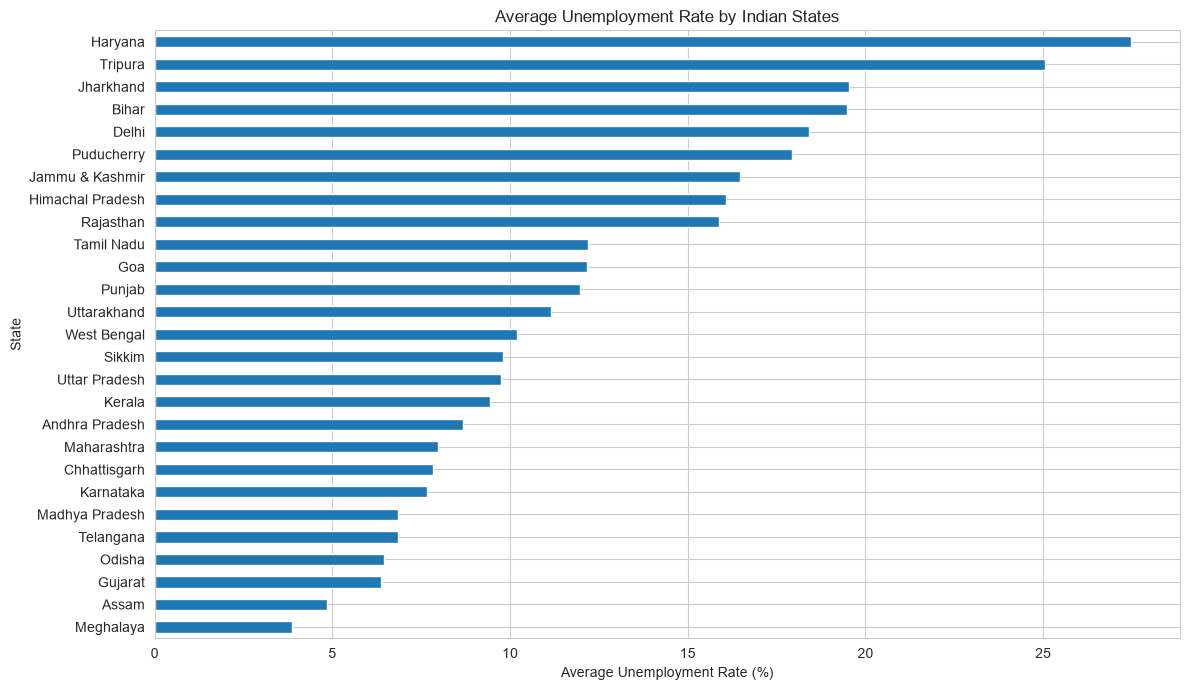

In [8]:
plt.figure(figsize=(12, 7))

state_unemployment.sort_values().plot(kind="barh")

plt.title("Average Unemployment Rate by Indian States")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("State")

plt.tight_layout()
plt.show()

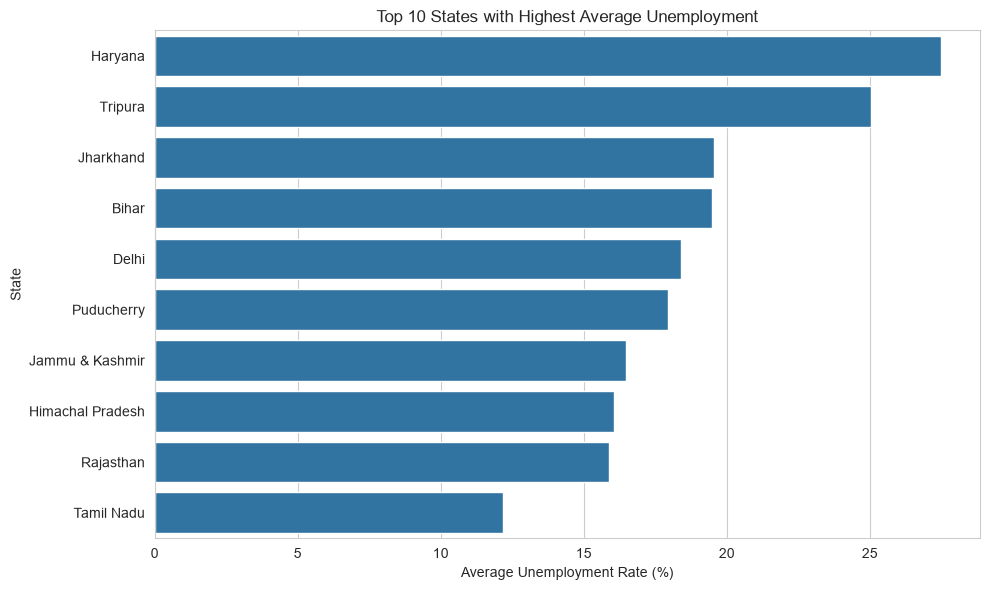

In [9]:
top_10_states = state_unemployment.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_states.values,
    y=top_10_states.index
)

plt.title("Top 10 States with Highest Average Unemployment")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("State")

plt.tight_layout()
plt.show()

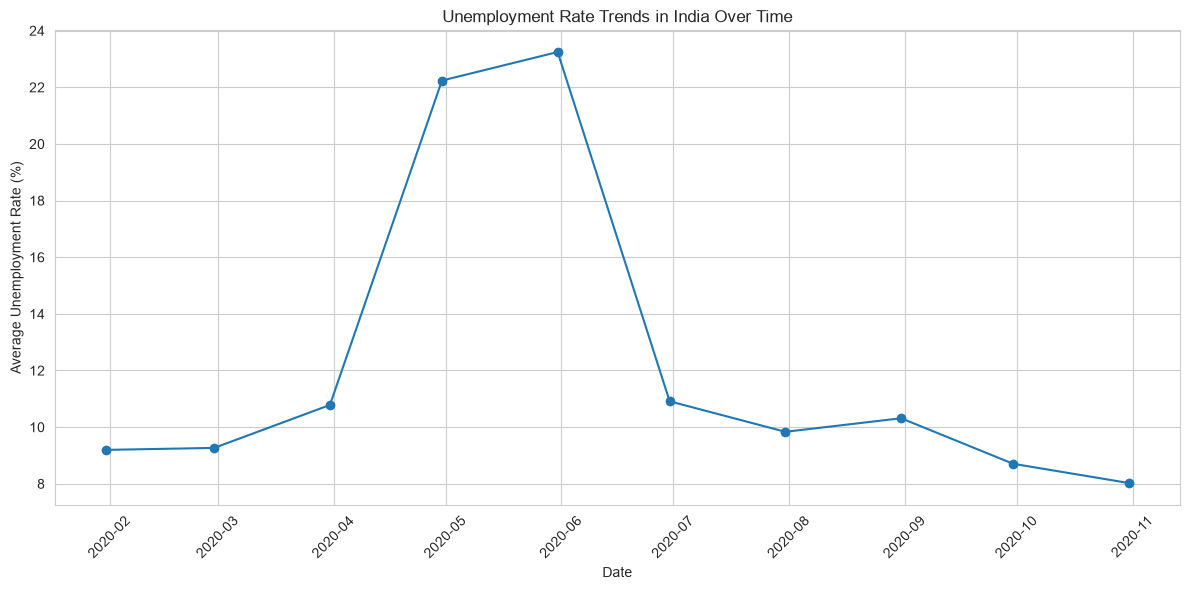

In [10]:
monthly_unemployment = (
    df.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_unemployment.index,
    monthly_unemployment.values,
    marker="o"
)

plt.title("Unemployment Rate Trends in India Over Time")
plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

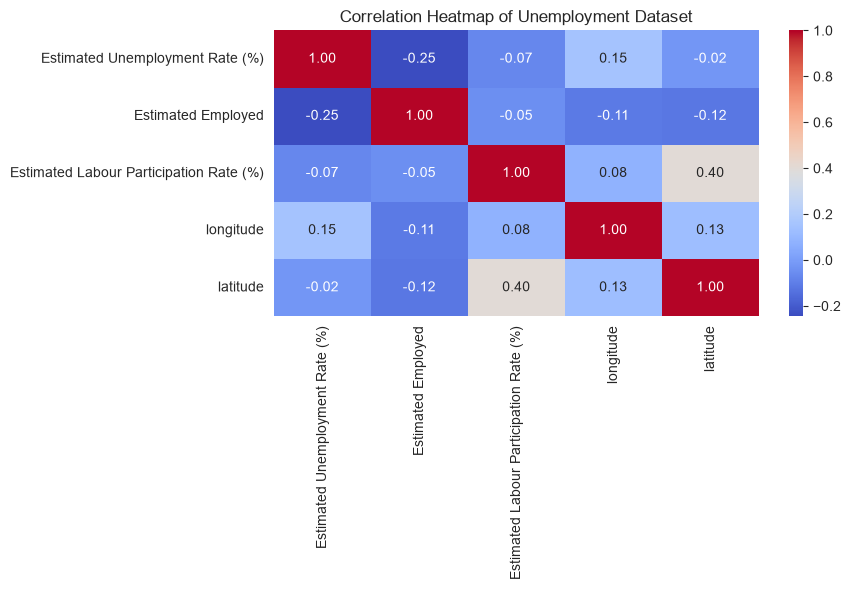

In [11]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(9, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Unemployment Dataset")
plt.tight_layout()
plt.show()

Average Unemployment Before COVID-19: 9.23
Average Unemployment During COVID-19: 12.96


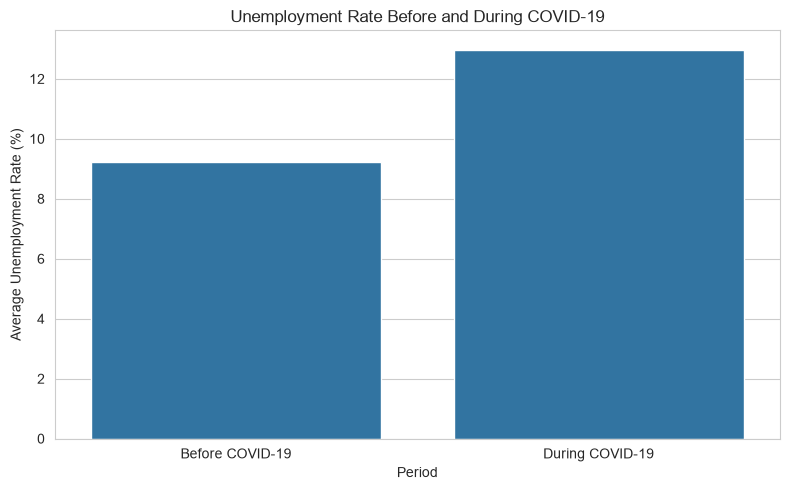

In [12]:
before_covid = df[df["Date"] < "2020-03-01"]

during_covid = df[df["Date"] >= "2020-03-01"]

before_rate = before_covid["Estimated Unemployment Rate (%)"].mean()

during_rate = during_covid["Estimated Unemployment Rate (%)"].mean()

print("Average Unemployment Before COVID-19:", round(before_rate, 2))

print("Average Unemployment During COVID-19:", round(during_rate, 2))

comparison = pd.DataFrame({
    "Period": ["Before COVID-19", "During COVID-19"],
    "Unemployment Rate": [before_rate, during_rate]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x="Period",
    y="Unemployment Rate"
)

plt.title("Unemployment Rate Before and During COVID-19")
plt.ylabel("Average Unemployment Rate (%)")

plt.tight_layout()
plt.show()

In [13]:
# State with highest average unemployment
highest_state = state_unemployment.idxmax()
highest_rate = state_unemployment.max()

# State with lowest average unemployment
lowest_state = state_unemployment.idxmin()
lowest_rate = state_unemployment.min()

# Month with highest average unemployment
highest_month = monthly_unemployment.idxmax()
highest_month_rate = monthly_unemployment.max()

# COVID-period percentage change
percentage_change = (
    (during_rate - before_rate) / before_rate
) * 100

print("KEY FINDINGS")
print("-" * 45)

print(f"Highest unemployment state: {highest_state}")
print(f"Average unemployment rate: {highest_rate:.2f}%")

print(f"\nLowest unemployment state: {lowest_state}")
print(f"Average unemployment rate: {lowest_rate:.2f}%")

print(f"\nHighest unemployment month: {highest_month}")
print(f"Unemployment rate: {highest_month_rate:.2f}%")

print(f"\nBefore COVID average: {before_rate:.2f}%")
print(f"During COVID average: {during_rate:.2f}%")
print(f"Percentage change: {percentage_change:.2f}%")

KEY FINDINGS
---------------------------------------------
Highest unemployment state: Haryana
Average unemployment rate: 27.48%

Lowest unemployment state: Meghalaya
Average unemployment rate: 3.87%

Highest unemployment month: 2020-05-31 00:00:00
Unemployment rate: 23.24%

Before COVID average: 9.23%
During COVID average: 12.96%
Percentage change: 40.43%


# Conclusion

The Unemployment Analysis in India project explored unemployment
patterns across different Indian states and time periods.

The analysis included:

1. Examining the overall unemployment rate.
2. Comparing unemployment rates across states.
3. Identifying states with the highest and lowest average rates.
4. Visualizing unemployment trends over time.
5. Studying relationships between numerical variables.
6. Comparing unemployment before and during the COVID-19 period.

The visualizations provided insights into regional differences
and changes in unemployment over time.

This project demonstrates the use of Python, Pandas, NumPy,
Matplotlib, and Seaborn for exploratory data analysis and
data visualization.